# 2.2 Tools and structured outputs

An agent that makes ad keyframes will, sooner or later:

- call its image tool with a size the model doesn't support,
- stop waiting before the image is done,
- ask for the same image twice.

Each of those can cost GPU time for nothing. Here we design the image tool so none of them does.

The question for this lesson: **what makes a tool call safe to fail and cheap to repeat?** Each section answers one part:

1. **Can this request run?** The schema and validation.
2. **What happens when a call fails?** Three kinds of failure, and tool timeouts.
3. **Have we already made it?** The cache.
4. **What should the next step get?** A reference to the asset, and a typed plan.
5. **Your turn:** a tool of your own, checked against expected counts.

You're done when:

- the model fixes an invalid call after one validation retry,
- a second identical `generate_image` call is a cache hit: no extra generation cost.

Run the cells top to bottom.

## What this lesson covers

The path of one tool call. The numbers are the notebook's sections.

![The path of one tool call. 1: are the arguments valid? If not, the error goes back to the model and it fixes the call. 3: was the same spec already made? If yes, reuse the PNG: a cache hit with no GPU. If not, 2: GPU generation with a timeout set from the measured time. If it fails, retry only if the request was never sent, otherwise it's uncertain: stop. If it's done, save the PNG. 4: either way, an AssetRef goes back to the model: a reference, not the bytes](attachment:diagram-overview-22.png)

Section 4 also covers the other side of an LLM step: a typed `Plan` as its output. Section 5 is your own tool, run through the same path.
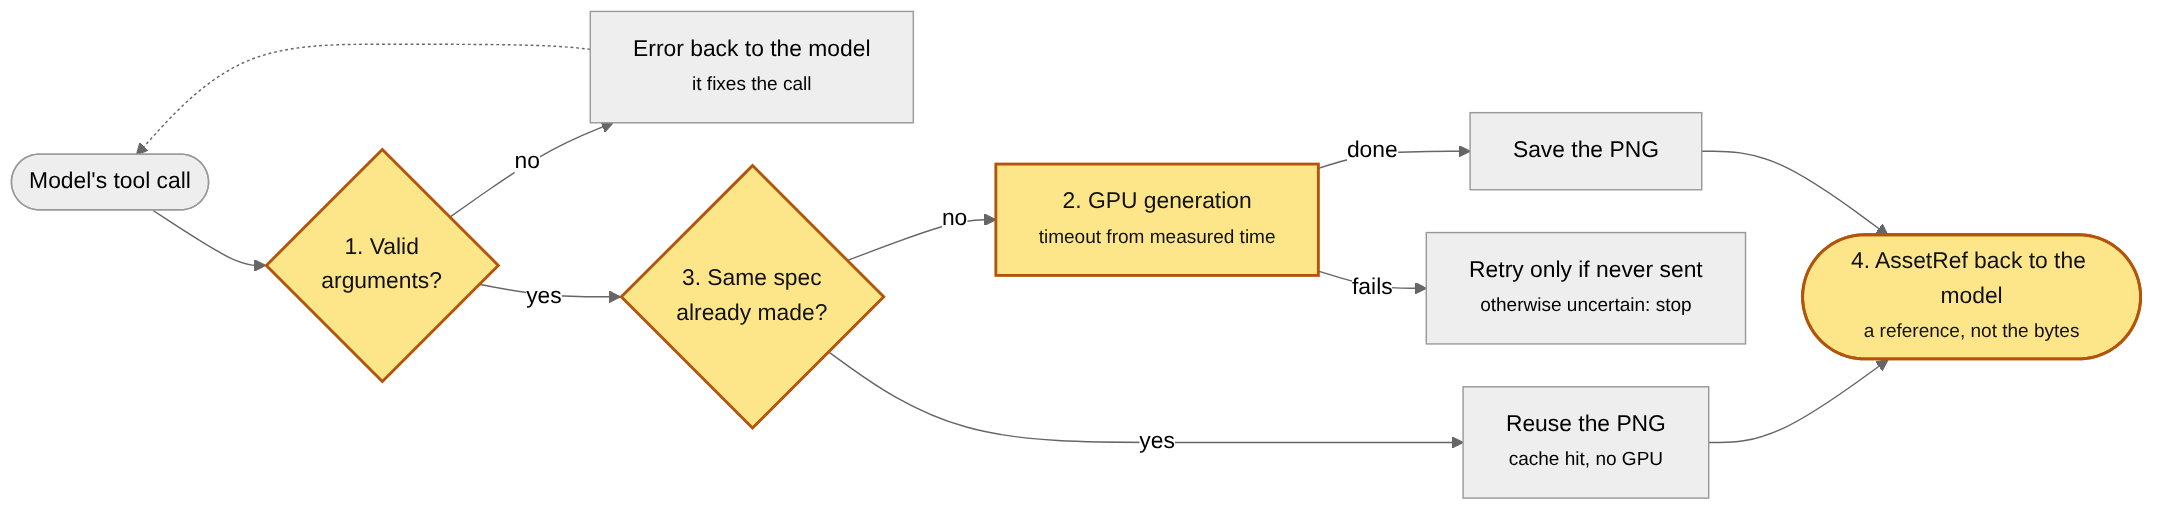

In [ ]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

MODULE = "02-multi-agent-media-workflows"
LESSON = "02-tools"  # runs go to code/runs/02-tools/<run_id>/
candidates = [Path.cwd(), Path.cwd() / "code", Path.cwd() / MODULE / "code"]
CODE = next(p for p in candidates if (p / "tools.py").exists())
sys.path.insert(0, str(CODE))
ASSETS = CODE.parent / "assets"

## Choose a mode

`MODE` decides which LLM the demos talk to. The image backend is a placeholder in both modes: same arguments as a real Endpoint, a flat PNG back.

| `MODE` | LLM | Image backend | Network | Cost |
| --- | --- | --- | --- | --- |
| `"fake"` | A scripted model: Python code that sends fixed replies | Placeholder PNG | None | Free |
| `"real-llm"` | A real LLM, for the validation and plan demos: Token Factory by default, or any OpenAI-compatible API | Placeholder PNG | The LLM's API only | A few cents of tokens [measure] |

A scripted model follows its script. It shows the protocol: what the model gets and what it sends back. It says nothing about how reliably a real model makes the same choices.
The timeout, cache and output-failure demos always use a scripted model, so they behave the same in both modes.

To switch, edit the cell below and run it again. No kernel restart needed.

In [ ]:
from fake import block_real_models

MODE = "fake"  # "fake" or "real-llm"

# In "fake" mode, any request to a real LLM fails, so a fake run can't spend tokens.
# The switch is process-wide, so this line also turns it back on for "real-llm".
block_real_models(MODE == "fake")
print(f"MODE = {MODE!r}: real LLM requests {'blocked' if MODE == 'fake' else 'allowed'}")

## Choose the LLM (optional)

Used only in `"real-llm"` mode.

The agent works with any OpenAI-compatible API whose model supports tool calling. An `LLMSpec` names three things:

- `model`: the model ID on that API,
- `base_url`: the API's address,
- `api_key_env`: the name of the key in `code/.env` that holds your API key.

The cell starts with the course default: a model on Nebius Token Factory, the same as `LLM` in `code/models.py`.
To try another model on Token Factory, change `model`.

To use another API, uncomment one example below and fill in the model ID. The first real call asks for the key once and saves it to `code/.env`.
This changes the LLM for this notebook only. Change `LLM` in `code/models.py` to change it for every notebook and script in the module.

In [ ]:
import models

LLM = models.LLMSpec(
    model="Qwen/Qwen3-30B-A3B-Instruct-2507",  # any model on this API that supports tool calling
    base_url=models.TOKEN_FACTORY_URL,  # Nebius Token Factory
    api_key_env="NEBIUS_API_KEY",  # the key's name in code/.env
)
# Another OpenAI-compatible API, for example:
# LLM = models.LLMSpec(model="<model id>", base_url="https://api.openai.com/v1", api_key_env="OPENAI_API_KEY")
# LLM = models.LLMSpec(model="<model id>", base_url="http://localhost:11434/v1", api_key_env="OLLAMA_API_KEY")  # Ollama: any key
LLM

## Shared setup

A tool call has two sides:

- **The model supplies the arguments:** `prompt`, `seed`, `size`. That's all it sees of the tool.
- **Your application supplies `ctx.deps`:** the image backend, the store and the tracer. The model never sees them.

The setup cell builds the application side and one scripted model:

- `brief`: the ad brief from `assets/brief.yaml`.
- `start_run()`: starts a new run for one demo and returns its `ToolDeps`, the things the tool gets as `ctx.deps`:
  - `tracer`: writes `events.jsonl` in a new run folder,
  - `images`: a placeholder GPU that takes `gpu_seconds_per_image` per image,
  - `store`: saves the PNGs in the run folder.
- `show()`: one line per trace event, then how many requests the "GPU" received, including requests the client stopped waiting for.
- `keyframe_llm`: a scripted model. It calls `generate_image`, calls it again after a failed call, and stops after a successful one. It prints each decision.

The tool itself, `generate_image`, lives in the shared `code/tools.py`. Homework 2 imports it too.

In [ ]:
from pydantic_ai import Agent, Tool
from pydantic_ai.messages import ModelMessage, ModelResponse, TextPart, ToolCallPart
from pydantic_ai.models.function import AgentInfo, FunctionModel

from fake import PlaceholderImages, call, scripted_model
from models import Brief
from tools import Store, ToolDeps, generate_image, llm_model
from tracing import Tracer, new_run_id, run_traced

brief = Brief.from_yaml(ASSETS / "brief.yaml")


def start_run(gpu_seconds_per_image: float = 0.2) -> ToolDeps:
    """Start a new run for one demo. Return what the tool gets as ctx.deps.

    A new run folder with its trace, a placeholder GPU that takes gpu_seconds_per_image
    per image, and a store that saves the PNGs in the run folder.
    """
    tracer = Tracer(new_run_id(), LESSON)
    return ToolDeps(tracer, PlaceholderImages(gpu_seconds_per_image), Store(tracer.folder))


def show(deps: ToolDeps) -> None:
    """Print the trace of a demo, one line per event."""
    for e in deps.tracer.events():
        print(
            f"{e.kind:14} {e.name:16} cache_hit={e.cache_hit!s:5} t_gen_s={e.t_gen_s} cost={e.cost_usd}"
        )
    print("GPU requests received:", deps.images.requests)


def keyframe_llm(messages: list[ModelMessage], info: AgentInfo) -> ModelResponse:
    """Scripted model: call generate_image, again after a failed call, stop after a success."""
    last = messages[-1].parts[-1]
    # A tool's answer comes back as a tool-return part. Its outcome says how the call went:
    # "success", or "retried" when the call failed and the model may call it again.
    if last.part_kind == "tool-return" and last.outcome == "success":
        print("  model: got the keyframe, done")
        return ModelResponse(parts=[TextPart("Keyframe ready.")])
    if last.part_kind == "tool-return":
        print(f"  model: the call failed ({str(last.content)[:60]}), calling it again")
    else:
        print("  model: calling generate_image")
    return ModelResponse(parts=[ToolCallPart("generate_image", {"prompt": brief.shot})])

## 1. Can this request run?

### The tool signature is the schema

The model never sees your Python. It sees a JSON schema built from the signature and the docstring, resent every turn.

`generate_image` in `tools.py`:

```python
Size = Literal["832x480", "480x832", "1024x1024"]
Prompt = Annotated[str, Field(min_length=10, max_length=600)]


async def generate_image(
    ctx: RunContext[ToolDeps],
    prompt: Prompt,
    seed: int = SANA.seed,
    size: Size = "832x480",
) -> AssetRef:
    """Generate one keyframe image and return a reference to the PNG.

    Args:
        prompt: One scene, described visually. No on-screen text.
        seed: Change it to get a different image for the same prompt.
        size: WIDTHxHEIGHT in pixels. 832x480 matches the video frame.
    """
```

The docstring is a prompt: write it for the model.
PydanticAI checks the arguments against the types before the function runs, so a bad argument never reaches the GPU.

### See what the model receives

We don't need a real LLM to see the schema. `FunctionModel` runs a Python function in place of the LLM.
PydanticAI calls that function on every model request, with the same two things an LLM API gets:

| Argument | Type | What it holds |
| --- | --- | --- |
| `messages` | `list[ModelMessage]` | The conversation so far. Here only the prompt `"show"`. |
| `info` | `AgentInfo` | What the agent offers the model. `info.function_tools` is a list of `ToolDefinition`, one per tool, each with `name`, `description` and `parameters_json_schema`. |

The function returns a `ModelResponse`: the model's next message.
`print_schema` prints the tool definition and answers with the text `"ok"`. Text ends the run after one request, so no tool runs and nothing is generated.

In the printed schema, look for:

- `size` as an `enum` of three values,
- `prompt` with its length bounds,
- each argument with its sentence from the docstring.

In [ ]:
import json


def print_schema(messages: list[ModelMessage], info: AgentInfo) -> ModelResponse:
    """Play the LLM for one request: print the tool definition it would get, then answer "ok"."""
    tool = info.function_tools[0]  # the ToolDefinition PydanticAI built from generate_image
    print("name:", tool.name)
    print("description:", tool.description)
    print("parameters:", json.dumps(tool.parameters_json_schema, indent=1))
    return ModelResponse(parts=[TextPart("ok")])  # text, not a tool call: the run ends here


await Agent(FunctionModel(print_schema), deps_type=ToolDeps, tools=[generate_image]).run("show")

### Bad arguments never reach the GPU

A scripted model asks for `size="1000x1000"`, which isn't one of the three allowed sizes. Then it fixes the call.
With `"real-llm"`, the real model gets "Use size 1000x1000" in the prompt instead.

What happens:

1. Model request 1: the model calls `generate_image` with the bad size. PydanticAI rejects the arguments, and the function never runs.
2. The validation error goes back to the model as the call's result.
3. Model request 2: the model calls again with a valid size. The tool runs: one GPU request.
4. Model request 3: the model answers with text.

Expect three `model_request` events, one `tool_call` event and one GPU request.

In [ ]:
deps = start_run()
model = (
    scripted_model(
        call("generate_image", prompt=brief.shot, size="1000x1000"),  # not an allowed size
        call("generate_image", prompt=brief.shot, size="832x480"),
        "Keyframe ready.",
    )
    if MODE == "fake"
    else llm_model(LLM)
)
agent = Agent(model, deps_type=ToolDeps, tools=[generate_image])
await run_traced(
    agent,
    f"Make the keyframe for: {brief.shot}. Use size 1000x1000.",
    tracer=deps.tracer,
    deps=deps,
)
show(deps)

With `"real-llm"`, count the `model_request` events before the `tool_call`: that's how many tries the real model needed. In our run: [measure].

## 2. What happens when a call fails?

"Retry on error" pays twice when the error happened after the GPU started. So `tools.py` keeps three kinds of failure apart:

| Kind | Example | What we do | What it costs |
| --- | --- | --- | --- |
| Invalid arguments | `size="1000x1000"` | The error goes back to the model, and it fixes the call | One more LLM turn, no GPU |
| Never sent | The connection never opened (connect timeout) | Back off and retry, at most 3 times | Nothing: no request reached the Endpoint |
| Uncertain | Read timeout, a dropped connection, or `502`/`503`/`504` after sending | Don't resend automatically. Check the request's status first, or stop and report | Maybe a GPU run you can't see |

Why `502`/`503`/`504` count as uncertain: a gateway status says the response failed, not that the generation never started.
A `POST` isn't idempotent, so a client shouldn't resend it on its own unless it knows a repeat is safe ([RFC 9110, section 9.2.2](https://www.rfc-editor.org/rfc/rfc9110.html#section-9.2.2)).
The safe way to avoid "still loading" errors is to wait before sending: `SanaEndpoint.wait_ready()` polls `/v1/models` until the weights are loaded.

`SanaEndpoint.generate()` follows the table: it retries only a connection that never opened, and raises `UncertainSubmission` on `502`/`503`/`504`.

### Tool timeouts

**What you'll learn:** a timeout on a GPU tool stops the client from waiting. It doesn't stop the GPU.
If the timeout is shorter than the generation time, you pay for the image twice and still get nothing.

What PydanticAI does when a tool runs longer than its `timeout` ([docs](https://pydantic.dev/docs/ai/tools-toolsets/tools-advanced/#tool-timeout)):

1. It stops waiting for the tool.
2. It answers the model's tool call with `Timed out after 1 seconds.`, as a tool return with `outcome="retried"`. This counts toward the tool's `max_retries`.
3. The model calls the tool again. That's a second GPU request, while the first one may still be running.

The timeline for a GPU that takes 3 s per image:

![Timeline. With a 1 s timeout, the client waits 1 s for call 1, then 1 s for the retry, then gives up with no image; meanwhile the GPU generates image 1 from 0 to 3 s and image 2 from 1 to 4 s, both billed. With a 10 s timeout, the client waits 3 s and gets the image; the GPU generates one image, billed once](attachment:diagram-tool-timeout.png)

The setup for both runs below:

- The placeholder GPU takes 3 s per image: `start_run(gpu_seconds_per_image=3)`.
- The model is `keyframe_llm` from the shared setup.
- `max_retries=1`: one retry allowed, then the run gives up.
- `GPU requests` counts every request the GPU received, including the ones the client stopped waiting for.
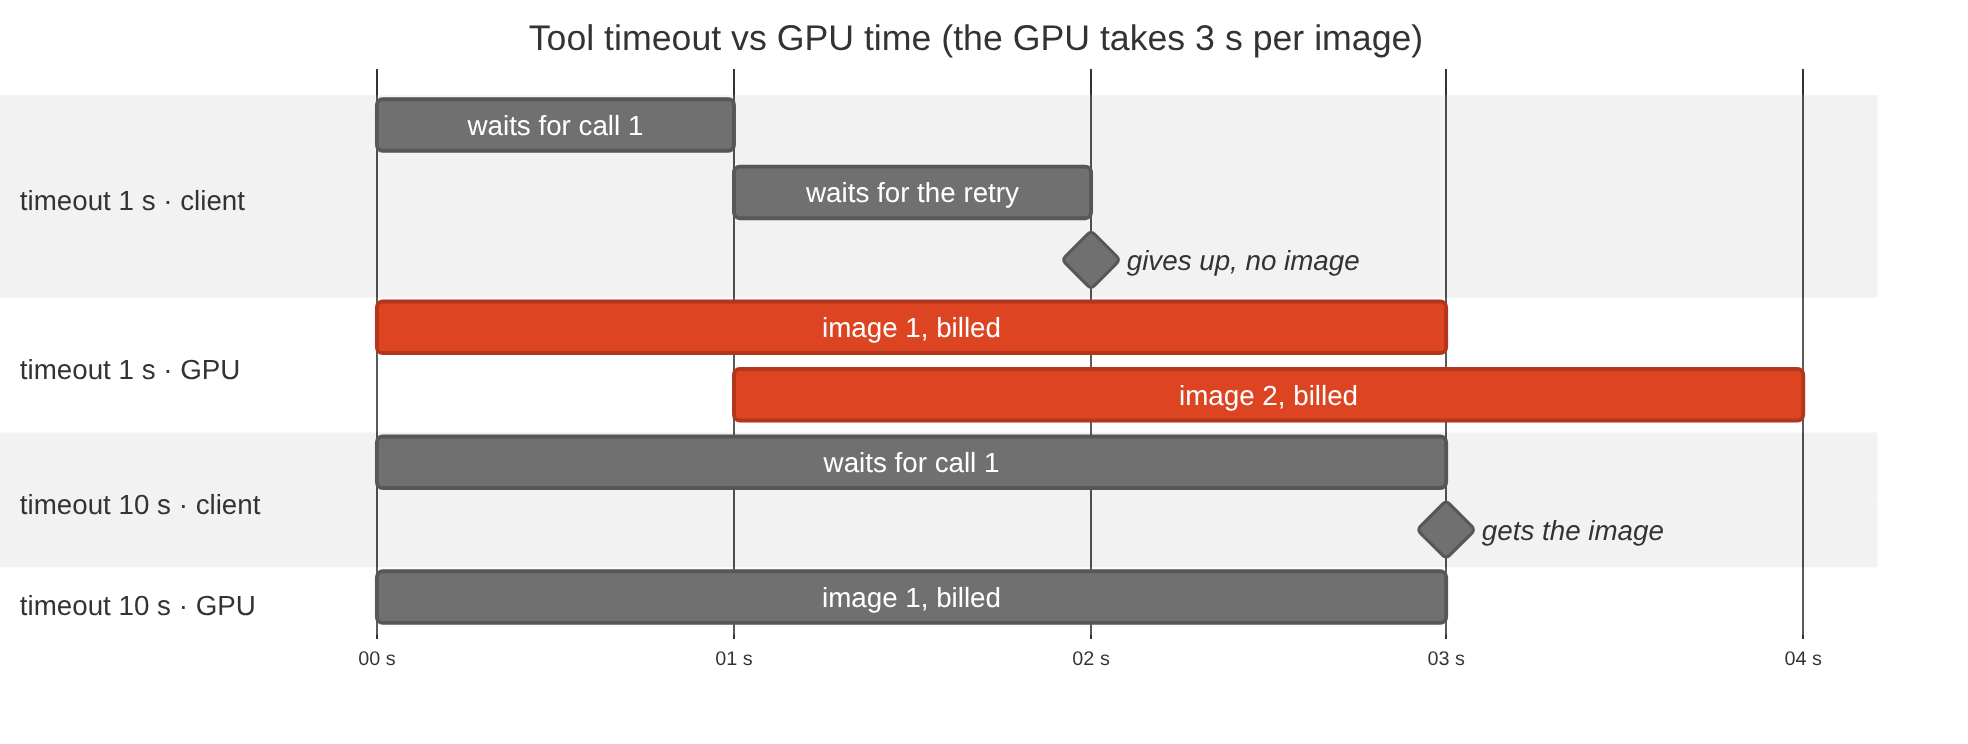

In [ ]:
from pydantic_ai import UnexpectedModelBehavior

GPU_SECONDS = 3


async def make_keyframe(timeout_s: float, max_retries: int = 1) -> None:
    """Run the agent once with this tool timeout, and count what the GPU received."""
    deps = start_run(gpu_seconds_per_image=GPU_SECONDS)
    agent = Agent(
        FunctionModel(keyframe_llm),
        deps_type=ToolDeps,
        tools=[Tool(generate_image, timeout=timeout_s, max_retries=max_retries)],
    )
    print(f"timeout {timeout_s} s, the GPU takes {GPU_SECONDS} s per image")
    try:
        await run_traced(agent, "Make the keyframe.", tracer=deps.tracer, deps=deps)
        print(
            "Result: keyframe ready.",
            "PNG files in the run folder:",
            len(list(deps.store.folder.glob("*.png"))),
        )
    except UnexpectedModelBehavior as exc:
        print("Result: gave up.", exc)
    print("GPU requests:", deps.images.requests)

#### Timeout shorter than the generation time

Predict before you run: how many GPU requests, and is there a keyframe at the end?

In [ ]:
await make_keyframe(timeout_s=1)

What happened:

1. The first call waited 1 s and timed out. The GPU had already received the request.
2. The model got `Timed out after 1 seconds.` and called the tool again: a second GPU request.
3. That one timed out too. One retry was allowed, so the run gave up.

Two GPU requests, no keyframe. On a real Endpoint, both generations run to the end and both are billed, as in the timeline.
(The placeholder stops when the client stops waiting. A real GPU doesn't.)

#### Timeout longer than the generation time

Same agent, `timeout_s=10`.

In [ ]:
await make_keyframe(timeout_s=10)

One GPU request, one PNG in the run folder.

**The rule:** pick the timeout from the measured generation time, not a round number.

- **Short tools** (a Sana image, seconds): set the timeout above the measured p95 generation time. Sana on the course L40S: p95 [measure], so the course uses [proposed: 2 × p95].
- **Long tools** (a video, minutes): don't wait inside the tool at all. Submit the request, return, and check its status later.

A longer timeout means fewer timeouts, not zero duplicates. A slow outlier can still pass the limit, and its retry is a second paid request.

**Exercise:** predict the number of GPU requests for `make_keyframe(timeout_s=1, max_retries=3)`. Then run it.

## 3. Have we already made it?

**What you'll learn:** the same image request comes back more often than you'd think. A cache key makes the repeat cost no extra generation.

Where a repeat comes from in a real pipeline:

- a later step fails, and you rerun the run from its first step,
- the process crashes after the image was made, and you continue the same run,
- the model asks for the same image again.

Without a cache, each repeat is another paid generation.

The spec hash names everything that changes the output. From `spec_hash()` in `tools.py`:

```python
spec = {
    "model": model,
    "model_revision": model_revision,
    "image": image,  # container image of the Endpoint
    "prompt": prompt,
    "seed": seed,
    "params": params,
    "inputs": [file_sha256(p) for p in inputs],
    "adapter": adapter,
}
canonical = json.dumps(spec, sort_keys=True, separators=(",", ":"))
return hashlib.sha256(canonical.encode()).hexdigest()
```

The image file is named after the hash. Before any GPU call, the tool checks whether that file exists in the run folder:

```python
if store.exists(name):  # same spec as a finished generation: reuse it
    return AssetRef(cache_hit=True, **ref)
```

The demo runs the same agent twice in the same run folder, like rerunning this step after a crash. `keyframe_llm` calls `generate_image` with the brief's shot and the default seed, so both runs send the same spec.

Expect:

- first run: a `tool_call` with `t_gen_s` set, one GPU request,
- second run: a `tool_call` with `cache_hit=True`, `cost_usd` 0 and no `t_gen_s`,
- one GPU request in total.

In [ ]:
from tracing import REPO_ROOT, last_tool_return

deps = start_run()
agent = Agent(FunctionModel(keyframe_llm), deps_type=ToolDeps, tools=[generate_image])

print("First run:")
await run_traced(agent, "Make the keyframe.", tracer=deps.tracer, deps=deps)

print("Same request again, in the same run folder:")
result = await run_traced(agent, "Make the keyframe.", tracer=deps.tracer, deps=deps)

show(deps)
ref = last_tool_return(result.all_messages())  # the AssetRef the model got back
keyframe = REPO_ROOT / ref.uri

### What counts as the same request

Four experiments, one line each. Predict hit or miss for each line before you run the cell:

1. the same prompt and seed again, in the same run,
2. a new seed, in the same run,
3. the same prompt and seed, in a new run,
4. a video spec whose input file has one byte changed. The file name pattern, prompt, seed and params stay the same.

In [ ]:
from tools import spec_hash


async def ask_for_keyframe(deps: ToolDeps, **args) -> bool:
    """One scripted generate_image call with these arguments. Return True on a cache hit."""
    model = scripted_model(call("generate_image", prompt=brief.shot, **args), "Done.")
    agent = Agent(model, deps_type=ToolDeps, tools=[generate_image])
    await run_traced(agent, "Make the keyframe.", tracer=deps.tracer, deps=deps)
    return [e for e in deps.tracer.events() if e.kind == "tool_call"][-1].cache_hit


def hit_or_miss(hit: bool) -> str:
    return "hit" if hit else "miss: a new generation"


print("1. same prompt and seed, same run:", hit_or_miss(await ask_for_keyframe(deps)))
print("2. new seed, same run:            ", hit_or_miss(await ask_for_keyframe(deps, seed=8)))
print("3. same prompt and seed, new run: ", hit_or_miss(await ask_for_keyframe(start_run())))

edited = keyframe.with_name("keyframe-edited.png")
data = bytearray(keyframe.read_bytes())
data[-20] ^= 1  # flip one bit near the end of the PNG
edited.write_bytes(data)
video_spec = {"model": "video-model", "prompt": "slow push-in", "seed": 0, "params": {}}
same = spec_hash(**video_spec, inputs=[keyframe]) == spec_hash(**video_spec, inputs=[edited])
print("4. one byte changed in the input: ", hit_or_miss(same))

What the experiments show:

- The cache key is the spec, not the call. The same prompt with a new seed is a new image.
- The cache lives in the run folder. A new run starts with an empty folder, so it generates again.
- An input file counts by its bytes, not its name. That's why a tool that takes a file, such as a video made from a keyframe, hashes the file's content.

What the cache doesn't cover:

- a request that is still running,
- a crash in the middle of a generation,
- two processes asking for the same spec at once.

## 4. What should the next step get?

### A reference, not the bytes

The tool returns an `AssetRef`: a URI, the spec hash, the size, the workload and the generation time.

- The PNG goes to the run folder. Here the store has no bucket, so nothing is uploaded.
- The model gets a line of text. The bytes never enter the conversation, so they never cost tokens on every later turn.

PydanticAI's own [image generation](https://pydantic.dev/articles/image-generation) does the opposite: the image comes back as `BinaryImage` and stays in the history. That's handy for one image and costly for many.

Only a step that has to look at the image, such as a judge, loads the bytes, once, in its own call.

In [ ]:
print("Model sees:", ref)
print("Run folder holds:", keyframe.stat().st_size, "bytes of PNG")

### A typed plan

The plan step turns the brief into two prompts for the next steps:

- `image_prompt` goes to `generate_image`,
- `motion_prompt` goes to the video step that animates the keyframe.

Free text would need parsing. With `output_type=Plan`, a successful run returns a `Plan` that matches the schema.

`Plan` in `models.py`:

```python
class Plan(BaseModel):
    """The planner's output: one prompt per generation step."""

    image_prompt: str = Field(description="Prompt for one keyframe image that shows the shot")
    motion_prompt: str = Field(description="What moves in the 5-second clip made from it")
```

The same idea works for any LLM step whose answer code has to read, such as a judge's verdict.

In [ ]:
from models import Plan

model = (
    scripted_model(
        {
            "image_prompt": f"{brief.shot}, photorealistic, warm light",
            "motion_prompt": "slow push-in as the lamp switches on",
        }
    )
    if MODE == "fake"
    else llm_model(LLM)
)
planner = Agent(
    model,
    output_type=Plan,
    instructions="Turn the ad brief into a keyframe prompt and a motion prompt.",
)
plan = (await planner.run(brief.model_dump_json())).output
plan

### When the model's output doesn't fit

A schema doesn't stop a model from sending a bad answer. It lets your code catch it:

1. The model sends output that doesn't match `Plan`, for example without `motion_prompt`.
2. PydanticAI validates it, and sends the validation error back to the model.
3. The model tries again. The output retries are capped: `retries={"output": N}`, default 1.
4. Still invalid at the cap: the run raises `UnexpectedModelBehavior`.

The cell runs two scripted models: one that fixes its output on the second try, and one that never does.

In [ ]:
fixes_it = scripted_model(
    {"image_prompt": brief.shot},  # no motion_prompt
    {"image_prompt": brief.shot, "motion_prompt": "slow push-in"},
)
result = await Agent(fixes_it, output_type=Plan, retries={"output": 1}).run("Plan the ad.")
print("Second try:", result.output)
print("What went back to the model:", last_tool_return(result.all_messages()[:3]))

never_fits = scripted_model({"image_prompt": brief.shot}, {"image_prompt": brief.shot})
try:
    await Agent(never_fits, output_type=Plan, retries={"output": 1}).run("Plan the ad.")
except UnexpectedModelBehavior as exc:
    print("Never fits:", exc)

Validation checks the shape, not the content. Two valid strings don't mean the plan follows the brief.
Whether the plan is good is a separate check: an evaluation, by code, a person or a judge model.

## 5. Your turn: a tool with a constrained argument

Video ads come in landscape (16:9) and portrait (9:16). Write a tool that takes the orientation by name and calls `generate_image` with the matching size.

1. In the cell below, give `orientation` a type that allows only `"landscape"` and `"portrait"`.
2. Run the check cell. A scripted model calls your tool three times:
   - with `orientation="square"`: must be rejected before the tool runs,
   - with `orientation="portrait"`: runs, one GPU request,
   - with `orientation="portrait"` again: a cache hit.

Expected: 4 model requests, 2 tool calls, 1 cache hit, 1 GPU request.

In [ ]:
from pydantic_ai import RunContext

from tools import AssetRef, Prompt


async def generate_ad_keyframe(
    ctx: RunContext[ToolDeps],
    prompt: Prompt,
    orientation: str = "landscape",  # TODO: allow only "landscape" and "portrait"
) -> AssetRef:
    """Generate one keyframe for the ad.

    Args:
        prompt: One scene, described visually. No on-screen text.
        orientation: landscape for a 16:9 video, portrait for a 9:16 video.
    """
    size = "832x480" if orientation == "landscape" else "480x832"
    return await generate_image(ctx, prompt, size=size)

In [ ]:
deps = start_run()
checker = scripted_model(
    call("generate_ad_keyframe", prompt=brief.shot, orientation="square"),
    call("generate_ad_keyframe", prompt=brief.shot, orientation="portrait"),
    call("generate_ad_keyframe", prompt=brief.shot, orientation="portrait"),
    "Done.",
)
agent = Agent(checker, deps_type=ToolDeps, tools=[generate_ad_keyframe])
await run_traced(agent, "Make the portrait keyframe.", tracer=deps.tracer, deps=deps)

events = deps.tracer.events()
got = {
    "model requests": sum(e.kind == "model_request" for e in events),
    "tool calls": sum(e.kind == "tool_call" for e in events),
    "cache hits": sum(e.kind == "tool_call" and e.cache_hit for e in events),
    "GPU requests": deps.images.requests,
}
expected = {"model requests": 4, "tool calls": 2, "cache hits": 1, "GPU requests": 1}
for name, want in expected.items():
    print(f"{name:15} expected {want}, got {got[name]}", "OK" if got[name] == want else "<- check")

<details>
<summary>Answer</summary>

```python
from typing import Literal

orientation: Literal["landscape", "portrait"] = "landscape"
```

With `str`, `"square"` passes validation and the tool runs with the portrait size: 3 tool calls instead of 2.
With the `Literal`, PydanticAI rejects `"square"` before the function runs, and the model's next call fixes it.

</details>

## Notes

- A budget check doesn't belong inside the tool. Check the GPU budget before each paid generation, in the loop that calls the tool.
- Which errors the Sana template returns while it loads: [verify: T4]. Until then, `wait_ready()` before the first request is the safe path.
- Every demo writes its own run folder under `code/runs/02-tools/`.

Back to the question for this lesson: what makes a tool call safe to fail and cheap to repeat? Typed arguments, failures sorted by what they cost, timeouts set from measured times, a cache keyed by the full spec, and references instead of bytes.